# 01 · Preprocesamiento: datos, contrato, fuga y Pipeline

Notebook de la fase 1. Es narrativa: toda la lógica vive en `src/fraud_detection/` y aquí
solo se importa. Cada cifra sale de una función con test; las celdas solo seleccionan y
dibujan lo que esas funciones devuelven. El notebook trabaja **solo con el periodo de
referencia**.

## 1. El problema y la rúbrica

Una plataforma de pagos móviles procesa millones de transacciones, y una fracción diminuta
es fraude. El objetivo es una probabilidad ordenable por transacción, para priorizar
revisiones, sobre PaySim: una simulación de transacciones móviles con etiqueta de fraude.
El error es asimétrico: un fraude que pasa cuesta el monto, y una transacción legítima
bloqueada cuesta fricción con el cliente y una revisión.

La rúbrica del Curso III pesa así: técnicas avanzadas de ML (optimización de
hiperparámetros, registro en MLflow e interpretabilidad local y global), 50%; monitoreo de
desempeño y de drift con su interpretación, 30%; repositorio y documentación, 20%. Este es
el primero de los cuatro notebooks obligatorios: deja los datos validados, el contrato
cerrado y el Pipeline listo para la fase 2.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraud_detection.config import settings
from fraud_detection.data import loader, profiling
from fraud_detection.data.schema import COLUMN_SPECS, MODEL_ELIGIBLE_COLUMNS, TARGET_COLUMN
from fraud_detection.features.pipeline import CONFIGURATIONS, build_preprocessor
from fraud_detection.models.baseline import BASELINE_TYPES, SignatureRule

pd.set_option("display.float_format", "{:.6g}".format)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 80
LEGIT, FRAUD = "#4c72b0", "#c44e52"

## 2. El corte temporal y por qué es ley

El enunciado fija el corte: `step <= 400` es el periodo de **referencia**, con el que se
entrena y se ajusta todo; `step >= 401` es el periodo de **producción**, que solo se usa
para evaluar y monitorear. Ninguna fila de producción puede influir en el ajuste de nada:
ni del modelo, ni del preprocesador, ni de un umbral, ni de un estadístico.

Por eso los dos periodos viven en dos archivos parquet separados. Leer producción exige
nombrarla, y eso aparece en el diff; además, un test del proyecto falla si un notebook la
nombra. Este notebook lee solo referencia.

In [2]:
print("Último step de referencia:", settings.REFERENCE_LAST_STEP)
print("Primer step de producción:", settings.PRODUCTION_FIRST_STEP)

reference = loader.read_reference()
steps = profiling.step_distribution(reference)
print(f"Referencia: steps {steps.first} a {steps.last}, {steps.distinct} steps distintos")

Último step de referencia: 400
Primer step de producción: 401


Referencia: steps 1 a 400, 400 steps distintos


## 3. El contrato de datos: qué significa "cuándo existe"

Cada columna del CSV lleva en el esquema (`src/fraud_detection/data/schema.py`) la marca de
**cuándo existe** respecto de la transacción. Es el dato central del proyecto: una columna
puede correlacionar fuerte con el fraude y aun así no existir en el momento de decidir.

| Valor | Significado |
|---|---|
| `PRE_TRANSACTION` | Existía antes de la transacción; está disponible al decidir |
| `POST_TRANSACTION` | Solo existe después de que la transacción se ejecutó |
| `SYSTEM_OUTPUT` | Es la salida de otro sistema de decisión |
| `TARGET` | Es la etiqueta |
| `IDENTIFIER` | Identifica una entidad; no mide el fenómeno |

Solo las columnas `PRE_TRANSACTION` son **elegibles**. Elegible no es lo mismo que
seleccionada: la selección pertenece a cada configuración del experimento (ADR 0006).

In [3]:
pd.DataFrame(
    [
        {
            "columna": spec.name,
            "dtype": str(spec.dtype),
            "cuándo existe": spec.availability.name,
            "elegible": spec.name in MODEL_ELIGIBLE_COLUMNS,
            "no negativa": spec.non_negative,
        }
        for spec in COLUMN_SPECS
    ]
)

,columna,dtype,cuándo existe,elegible,no negativa
0,step,int16,PRE_TRANSACTION,True,False
1,type,category,PRE_TRANSACTION,True,False
2,amount,float64,PRE_TRANSACTION,True,True
3,nameOrig,string,IDENTIFIER,False,False
4,oldbalanceOrg,float64,PRE_TRANSACTION,True,True
5,newbalanceOrig,float64,POST_TRANSACTION,False,False
6,nameDest,string,IDENTIFIER,False,False
7,oldbalanceDest,float64,PRE_TRANSACTION,True,True
8,newbalanceDest,float64,POST_TRANSACTION,False,False
9,isFraud,int8,TARGET,False,False


## 4. Las mediciones

### 4.1 El desbalance de clases

In [4]:
balance = profiling.class_balance(reference)
balance

,rows,proportion
isFraud,,
0,5782553,0.999226
1,4477,0.000773627
total,5787030,1


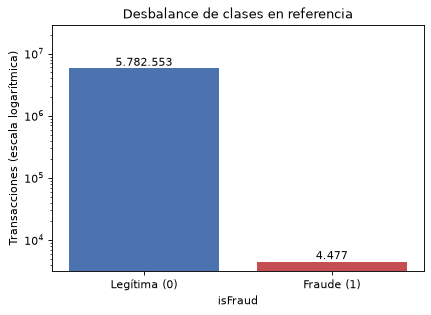

In [5]:
classes = balance.loc[[0, 1], "rows"]
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Legítima (0)", "Fraude (1)"], classes, color=[LEGIT, FRAUD])
ax.set_yscale("log")
ax.set_ylim(top=classes.max() * 5)
ax.set_title("Desbalance de clases en referencia")
ax.set_xlabel("isFraud")
ax.set_ylabel("Transacciones (escala logarítmica)")
ax.bar_label(bars, labels=[f"{value:,}".replace(",", ".") for value in classes])
plt.show()

El fraude es el 0,0774% de las transacciones de referencia: 4.477 de 5.787.030. Un
clasificador que siempre responde "legítima" acierta el 99,92% de las veces. Por eso la
accuracy no decide nada en este proyecto. La métrica de decisión es el recall con
precisión ≥ 0,99, declarada antes de medir (`docs/adr/0009-evaluation-design.md`); el
PR-AUC global queda como contexto, porque la firma del simulador lo satura.

### 4.2 El fraude por tipo de transacción

In [6]:
by_type = profiling.label_by_type(reference)
print("Tipos sin ninguna fila positiva:", list(by_type.types_without_positives))
by_type.counts

Tipos sin ninguna fila positiva: ['CASH_IN', 'DEBIT', 'PAYMENT']


isFraud,0,1,total
type,,,
CASH_IN,1271367,0,1271367
CASH_OUT,2045848,2248,2048096
DEBIT,37116,0,37116
PAYMENT,1949011,0,1949011
TRANSFER,479211,2229,481440
total,5782553,4477,5787030


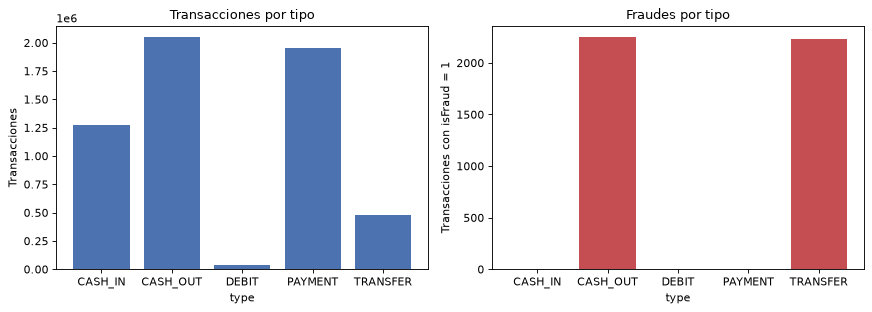

In [7]:
per_type = by_type.counts.drop(index="total")
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.bar(per_type.index, per_type["total"], color=LEGIT)
left.set_title("Transacciones por tipo")
left.set_xlabel("type")
left.set_ylabel("Transacciones")
right.bar(per_type.index, per_type[1], color=FRAUD)
right.set_title("Fraudes por tipo")
right.set_xlabel("type")
right.set_ylabel("Transacciones con isFraud = 1")
fig.tight_layout()
plt.show()

El fraude ocurre solo en `TRANSFER` y `CASH_OUT`. `CASH_IN`, `DEBIT` y `PAYMENT` no tienen
ninguna fila positiva en referencia.

### 4.3 Filas por step: el ciclo diario y un hueco de tres días

In [8]:
weekly = profiling.daily_volume_autocorrelation(reference)
weekly.daily_rows.astype(int).to_frame("filas por día completo").T

day,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
filas por día completo,452761,6749,21904,12995,440626,420282,449147,418103,392886,418006,349800,429335,398210,400706,375514


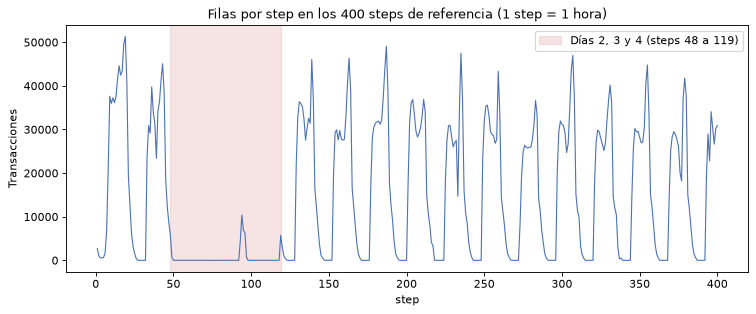

count       400
mean    14467.6
std     15444.2
min           2
25%          14
50%      7908.5
75%     29288.2
max       51352
Name: count, dtype: float64

In [9]:
day = profiling.STEPS_PER_DAY
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(steps.rows_per_step.index, steps.rows_per_step.to_numpy(), color=LEGIT, lw=1)
ax.axvspan(2 * day, 5 * day - 1, color=FRAUD, alpha=0.15, label="Días 2, 3 y 4 (steps 48 a 119)")
ax.set_title("Filas por step en los 400 steps de referencia (1 step = 1 hora)")
ax.set_xlabel("step")
ax.set_ylabel("Transacciones")
ax.legend(loc="upper right")
plt.show()
steps.summary

El volumen sigue un ciclo diario: picos de decenas de miles de filas por hora y valles
nocturnos de unas pocas. Además, los días 2, 3 y 4 están casi vacíos: 6.749, 21.904 y
12.995 filas, contra entre 349.800 y 452.761 en los otros doce días completos (tabla de
arriba). Es un hueco de la simulación, y explica buena parte de los 400 steps con muy pocas
filas: el 25% de los steps tiene 14 filas o menos.

### 4.4 La hora del día

In [10]:
by_hour = profiling.label_rate_by_hour(reference)
by_hour.T

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
rows,59751,23644,7713,1117,699,837,1824,7013,21273,274290,...,414615,397511,409860,397727,490675,575977,477022,211999,163916,119676
positives,148,202,198,178,144,178,186,188,188,205,...,209,207,195,173,191,158,202,185,177,183
rate,0.00247695,0.00854339,0.0256709,0.159355,0.206009,0.212664,0.101974,0.0268074,0.00883749,0.000747384,...,0.000504082,0.00052074,0.000475772,0.000434972,0.00038926,0.000274317,0.000423461,0.000872646,0.00107982,0.00152913


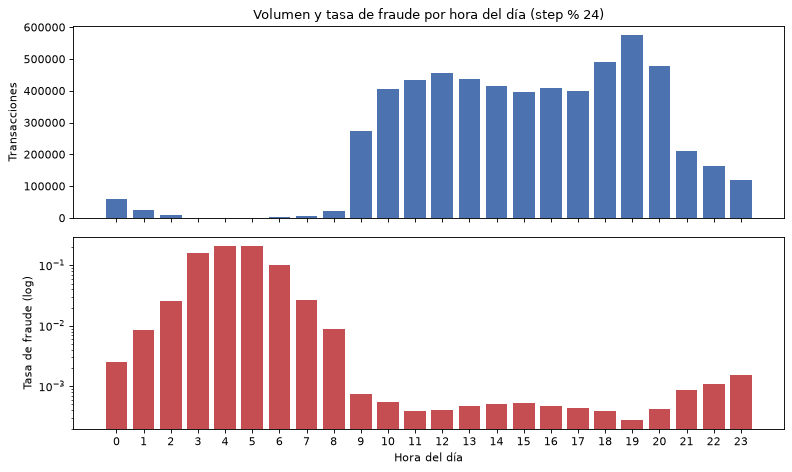

In [11]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
top.bar(by_hour.index, by_hour["rows"], color=LEGIT)
top.set_title("Volumen y tasa de fraude por hora del día (step % 24)")
top.set_ylabel("Transacciones")
bottom.bar(by_hour.index, by_hour["rate"], color=FRAUD)
bottom.set_yscale("log")
bottom.set_ylabel("Tasa de fraude (log)")
bottom.set_xlabel("Hora del día")
bottom.set_xticks(list(by_hour.index))
fig.tight_layout()
plt.show()

El número de fraudes por hora es casi constante (entre 144 y 221), mientras el volumen cae
de más de medio millón de filas a menos de mil. Por eso la tasa de fraude va de alrededor de
0,0004 durante el día a 0,21 a las 5. Es el mismo artefacto de volumen que el ADR 0006
registra para los steps: el simulador inyecta fraude de forma pareja en el tiempo.

El gráfico también justifica la **codificación cíclica** de la hora (ADR 0008): las horas 23
y 0 son vecinas en volumen y en tasa, y una hora ordinal cruda las pondría en los extremos
opuestos de la escala.

### 4.5 ¿Hay un ciclo semanal?

`day_of_week` se había propuesto razonando, no midiendo. El criterio, fijado antes de medir:
entra solo si la autocorrelación del volumen diario en el rezago 7 es la mayor de los
rezagos 1 a 8 **y** supera la banda 2/√n.

In [12]:
profiling.rows_per_step_by_day_of_cycle(reference)

,days,steps,rows,mean_rows_per_step
day_of_cycle,,,,
0,3,71,1420892,20012.6
1,3,72,1246378,17310.8
2,3,65,628602,9670.8
3,2,48,439910,9164.79
4,2,48,362795,7558.23
5,2,48,869961,18124.2
6,2,48,818492,17051.9


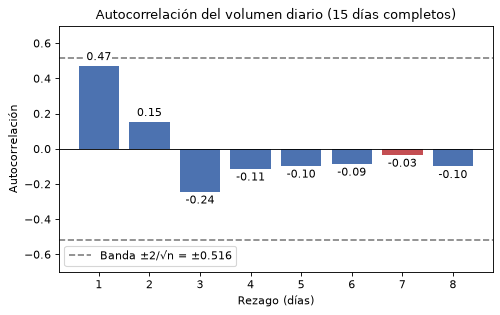

¿El rezago 7 es el mayor y supera la banda? False


In [13]:
acf = weekly.autocorrelation
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(acf.index, acf.to_numpy(), color=[FRAUD if lag == 7 else LEGIT for lag in acf.index])
ax.axhline(weekly.band, color="gray", ls="--", label=f"Banda ±2/√n = ±{weekly.band:.3f}")
ax.axhline(-weekly.band, color="gray", ls="--")
ax.axhline(0, color="black", lw=0.8)
ax.bar_label(
    bars, fmt="%.2f", padding=3, bbox={"facecolor": "white", "edgecolor": "none", "pad": 1}
)
ax.set_ylim(-0.7, 0.7)
ax.set_xticks(list(acf.index))
ax.set_title(f"Autocorrelación del volumen diario ({len(weekly.daily_rows)} días completos)")
ax.set_xlabel("Rezago (días)")
ax.set_ylabel("Autocorrelación")
ax.legend(loc="lower left")
plt.show()
print("¿El rezago 7 es el mayor y supera la banda?", weekly.peaks_at(7))

No hay estructura semanal. El rezago 7, en rojo, es casi cero y queda dentro de la banda; el
mayor es el rezago 1, y tampoco sale de ella. `day_of_week` no entra al modelo (ADR 0006).
Las diferencias de la tabla por posición del ciclo vienen de los días 2, 3 y 4, casi vacíos,
no de una periodicidad.

### 4.6 Las distribuciones de los montos

Filas con amount = 0, por clase: {0: 0, 1: 4}


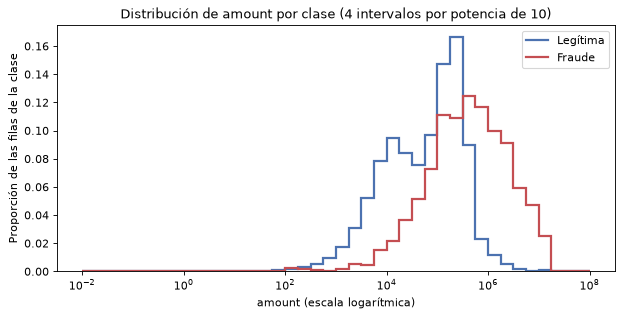

In [14]:
amount_histogram = profiling.log_histogram_by_label(reference, "amount")
print("Filas con amount = 0, por clase:", amount_histogram.zeros.to_dict())
fig, ax = plt.subplots(figsize=(9, 4))
ax.stairs(amount_histogram.shares[0], amount_histogram.edges, color=LEGIT, lw=2, label="Legítima")
ax.stairs(amount_histogram.shares[1], amount_histogram.edges, color=FRAUD, lw=2, label="Fraude")
ax.set_xscale("log")
ax.set_title("Distribución de amount por clase (4 intervalos por potencia de 10)")
ax.set_xlabel("amount (escala logarítmica)")
ax.set_ylabel("Proporción de las filas de la clase")
ax.legend()
plt.show()

`amount` ocupa cerca de diez órdenes de magnitud, de céntimos a decenas de millones, con la
mayor parte de las legítimas entre unos pocos miles y unos cientos de miles, y una cola
larga hacia la derecha. En escala lineal, un modelo lineal
vería casi solo la cola: es la evidencia de la cola pesada que justifica `log1p` en el
ADR 0008. El fraude se concentra en montos más altos que las legítimas. Las únicas 4 filas
con `amount = 0` son fraude, y quedan fuera de este eje logarítmico.

Filas con oldbalanceOrg = 0, por clase: {0: 1928966, 1: 29}
Proporción de la clase: {0: 0.3336, 1: 0.0065}


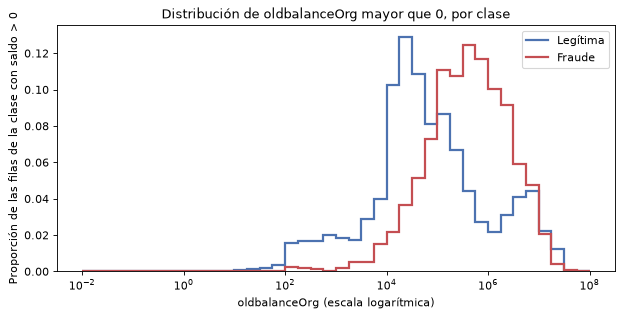

In [15]:
balance_histogram = profiling.log_histogram_by_label(reference, "oldbalanceOrg")
print("Filas con oldbalanceOrg = 0, por clase:", balance_histogram.zeros.to_dict())
print("Proporción de la clase:", balance_histogram.zero_shares.round(4).to_dict())
fig, ax = plt.subplots(figsize=(9, 4))
ax.stairs(balance_histogram.shares[0], balance_histogram.edges, color=LEGIT, lw=2, label="Legítima")
ax.stairs(balance_histogram.shares[1], balance_histogram.edges, color=FRAUD, lw=2, label="Fraude")
ax.set_xscale("log")
ax.set_title("Distribución de oldbalanceOrg mayor que 0, por clase")
ax.set_xlabel("oldbalanceOrg (escala logarítmica)")
ax.set_ylabel("Proporción de las filas de la clase con saldo > 0")
ax.legend()
plt.show()

Un tercio de las transacciones legítimas parte de un saldo de origen igual a cero, y solo 29
fraudes lo hacen: el fraude toma cuentas con dinero. Entre los saldos positivos, la curva
del fraude tiene la misma forma que la de su `amount`, porque el fraude se lleva el saldo
completo; es la firma de la sección 6 vista desde otro ángulo.

### 4.7 Calidad: nulos y duplicados

In [16]:
profiling.null_counts(reference)

,nulls,percent
step,0,0
type,0,0
amount,0,0
nameOrig,0,0
oldbalanceOrg,0,0
newbalanceOrig,0,0
nameDest,0,0
oldbalanceDest,0,0
newbalanceDest,0,0
isFraud,0,0


In [17]:
profiling.duplicate_rows(reference)

DuplicateRows(rows=5787030, redundant_copies=0, rows_in_duplicate_groups=0)

### 4.8 Los identificadores

In [18]:
profiling.identifier_repetition(reference)

,rows,distinct,values_repeated,rows_with_repeated_value,max_occurrences
nameOrig,5787030,5779296,7722,15456,3
nameDest,5787030,2466859,418521,3738692,112


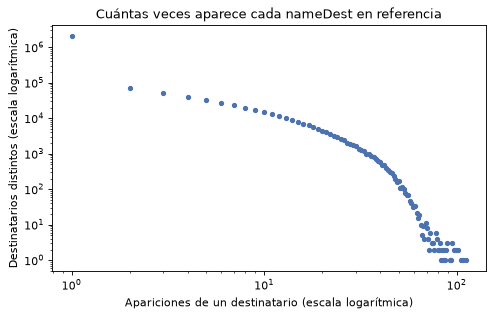

In [19]:
repetitions = profiling.occurrence_distribution(reference, "nameDest")
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(repetitions.index, repetitions.to_numpy(), s=14, color=LEGIT)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Cuántas veces aparece cada nameDest en referencia")
ax.set_xlabel("Apariciones de un destinatario (escala logarítmica)")
ax.set_ylabel("Destinatarios distintos (escala logarítmica)")
plt.show()

`nameOrig` casi no se repite, pero `nameDest` sí: 2.048.338 destinatarios aparecen una sola
vez, y la cola llega a uno que aparece 112 veces. Esa repetición es la que haría posible
una vía de agregados por destinatario (cuántas veces recibió, cuánto, de cuántos orígenes).

La vía se **declinó** (ADR 0006): la rúbrica del Curso III no premia feature engineering;
cualquier agregado tendría que ajustarse dentro del Pipeline solo con referencia, o
cruzaría el corte; y el criterio del proyecto es hacer lo necesario. Queda declinada, no
olvidada.

## 5. La caza de fuga: los hallazgos

### 5.1 La bandera del sistema, `isFlaggedFraud`

Es la salida de una regla de negocio, no una entrada. Si entrara como feature, el modelo
aprendería la regla en vez del fenómeno.

In [20]:
flag = profiling.flag_profile(reference)
print("Filas marcadas:", flag.flagged_rows)
flag.by_label

Filas marcadas: 4


isFraud,0,1
isFlaggedFraud,,
0,5782553,4473
1,0,4


In [21]:
flag.amount_stats

,rows,min,median,max
flagged,4,536624,3.1176e+06,4.95389e+06
not flagged,5.78703e+06,0,75630.3,9.24455e+07


Marca 4 filas, las 4 fraude: de 4.477 fraudes, cubre 4. Queda fuera por ser salida de otro
sistema de decisión, y además sería inútil.

### 5.2 La aritmética de los saldos

Los saldos posteriores a la transacción son `POST_TRANSACTION`. Además, la simulación los
escribe de un modo que filtra la etiqueta: el error
`oldbalanceOrg - amount - newbalanceOrig` es cero casi siempre en el fraude y rara vez en
las legítimas. La comparación se hace dentro de cada tipo, porque en `CASH_IN` el dinero
entra al origen y la fórmula no aplica.

In [22]:
profiling.balance_consistency(reference)

,rows,origin_zero,origin_share,destination_zero,destination_share
all,5787030,1112572,0.192253,1808244,0.312465
isFraud=0,5782553,1108128,0.191633,1806478,0.312401
isFraud=1,4477,4444,0.992629,1766,0.394461


In [23]:
consistency = profiling.balance_consistency_by_type(reference)
consistency

rows  origin_zero_share  destination_zero_share  destination_both_zero_share
type     isFraud                                                                                 
CASH_IN  0        1271367                  0                       0                     0.113872
CASH_OUT 0        2045848           0.103944                0.707938                  0.000774251
         1           2248           0.989324                0.785142                   0.00088968
DEBIT    0          37116           0.678279                0.684125                            0
PAYMENT  0        1949011           0.437715                       0                            1
TRANSFER 0         479211          0.0358652                0.694375                  0.000221197
         1           2229           0.995962             0.000448632                      0.98699

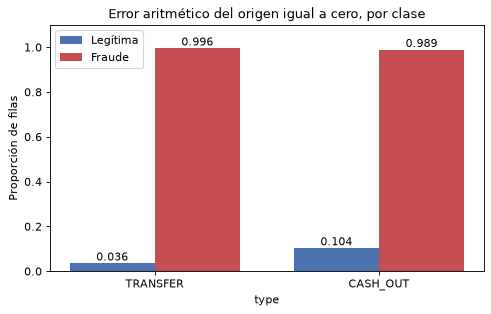

In [24]:
fraud_types = ["TRANSFER", "CASH_OUT"]
positions = np.arange(len(fraud_types))
width = 0.38
origin = consistency["origin_zero_share"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    positions - width / 2,
    [origin[(t, 0)] for t in fraud_types],
    width,
    label="Legítima",
    color=LEGIT,
)
ax.bar(
    positions + width / 2, [origin[(t, 1)] for t in fraud_types], width, label="Fraude", color=FRAUD
)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f")
ax.set_xticks(positions, fraud_types)
ax.set_ylim(0, 1.1)
ax.set_title("Error aritmético del origen igual a cero, por clase")
ax.set_xlabel("type")
ax.set_ylabel("Proporción de filas")
ax.legend()
plt.show()

Dentro de `TRANSFER` y de `CASH_OUT`, el saldo posterior del origen cuadra en casi todos
los fraudes y en una minoría de las legítimas. Es un artefacto de la simulación, y es otra
razón, además de la temporal, para dejar fuera `newbalanceOrig` y `newbalanceDest`.

### 5.3 Los saldos de destino en cero: el centinela de la imputación silenciosa

Para un comercio, un saldo de destino en cero no es un cero: la documentación dice que los
destinatarios `M` no tienen información de saldo, y el generador escribe 0 en su lugar. Es
la imputación silenciosa de `docs/METHODOLOGY.md`, sección 7.1.

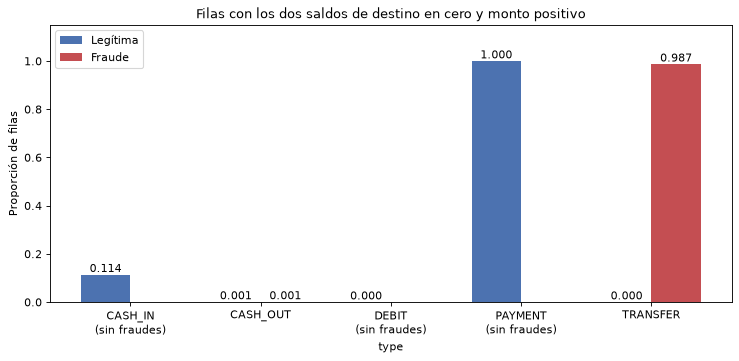

In [25]:
both_zero = consistency["destination_both_zero_share"]
types = list(both_zero.index.get_level_values(0).unique())
with_fraud = [t for t in types if (t, 1) in both_zero.index]
positions = {t: i for i, t in enumerate(types)}
fig, ax = plt.subplots(figsize=(11, 4.5))
legit_bars = ax.bar(
    [positions[t] - width / 2 for t in types],
    [both_zero[(t, 0)] for t in types],
    width,
    label="Legítima",
    color=LEGIT,
)
fraud_bars = ax.bar(
    [positions[t] + width / 2 for t in with_fraud],
    [both_zero[(t, 1)] for t in with_fraud],
    width,
    label="Fraude",
    color=FRAUD,
)
ax.bar_label(legit_bars, fmt="%.3f")
ax.bar_label(fraud_bars, fmt="%.3f")
ax.set_xticks(
    list(positions.values()),
    [t if t in with_fraud else f"{t}\n(sin fraudes)" for t in types],
)
ax.set_ylim(0, 1.15)
ax.set_title("Filas con los dos saldos de destino en cero y monto positivo")
ax.set_xlabel("type")
ax.set_ylabel("Proporción de filas")
ax.legend(loc="upper left")
plt.show()

In [26]:
profiling.destination_prefix_by_type(reference)

prefix,C,M
type,,
CASH_IN,1271367,0
CASH_OUT,2048096,0
DEBIT,37116,0
PAYMENT,0,1949011
TRANSFER,481440,0


En `PAYMENT`, el 100% de las filas tiene los dos saldos de destino en cero, y todas sus
filas, y solo ellas, van a un destinatario `M` (tabla de arriba): son los ceros de
"no sé" de los comercios. Un indicador de comercio sería idéntico a `type == PAYMENT`, que
el modelo ya tiene, y por eso no se agrega (ADR 0006). El otro extremo es `TRANSFER` con
fraude: casi siempre deja los dos saldos de destino en cero, frente a una fracción ínfima
de las transferencias legítimas. Es otro artefacto del generador.

## 6. La firma del simulador y el baseline

`amount_equals_origin_balance = (amount > 0) & (amount == oldbalanceOrg)`: la transacción
se lleva el saldo completo. Las dos columnas son `PRE_TRANSACTION`, así que **no es fuga**.
Es una firma determinista del generador: el agente de fraude de PaySim vacía la cuenta.

In [27]:
signature = profiling.signature_by_type(reference)
signature

rows  signature    share  zero_over_zero
type     isFraud                                             
CASH_IN  0        1271367          0        0               0
CASH_OUT 0        2045848          0        0               0
         1           2248       2219   0.9871               4
DEBIT    0          37116          0        0               0
PAYMENT  0        1949011          0        0               0
TRANSFER 0         479211          0        0               0
         1           2229       2166 0.971736               0

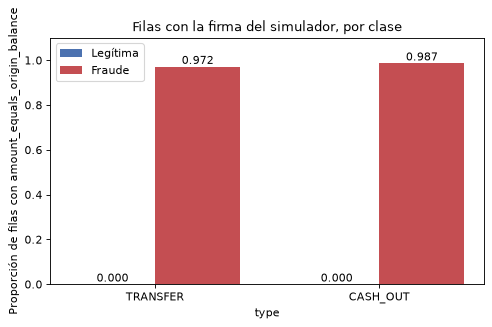

In [28]:
share = signature["share"]
positions = np.arange(len(fraud_types))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    positions - width / 2,
    [share[(t, 0)] for t in fraud_types],
    width,
    label="Legítima",
    color=LEGIT,
)
ax.bar(
    positions + width / 2, [share[(t, 1)] for t in fraud_types], width, label="Fraude", color=FRAUD
)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f")
ax.set_xticks(positions, fraud_types)
ax.set_ylim(0, 1.1)
ax.set_title("Filas con la firma del simulador, por clase")
ax.set_xlabel("type")
ax.set_ylabel("Proporción de filas con amount_equals_origin_balance")
ax.legend()
plt.show()

La firma separa casi por completo: ninguna transacción legítima la tiene, y la gran mayoría
de los fraudes sí.

Vista como imagen: `amount` contra `oldbalanceOrg`. Una muestra uniforme escondería el
fenómeno, porque con una tasa del 0,0774% una muestra de unas 24.000 filas tendría del
orden de 19 fraudes. Por eso se usan **todas** las filas positivas y una muestra de 20.000
negativas, tomada con la semilla de `config.py`.

In [29]:
NEGATIVE_SAMPLE = 20_000
sample = profiling.sample_with_all_positives(reference, negative_rows=NEGATIVE_SAMPLE)
print("Semilla:", settings.RANDOM_STATE)
profiling.class_balance(sample)

Semilla: 42


,rows,proportion
isFraud,,
0,20000,0.817094
1,4477,0.182906
total,24477,1


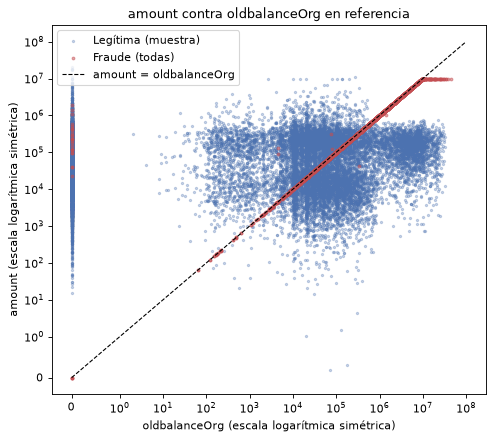

In [30]:
legit = sample[sample[TARGET_COLUMN] == 0]
fraud = sample[sample[TARGET_COLUMN] == 1]
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(
    legit["oldbalanceOrg"], legit["amount"], s=4, alpha=0.3, color=LEGIT, label="Legítima (muestra)"
)
ax.scatter(
    fraud["oldbalanceOrg"], fraud["amount"], s=6, alpha=0.5, color=FRAUD, label="Fraude (todas)"
)
ax.plot([0, 1e8], [0, 1e8], color="black", lw=1, ls="--", label="amount = oldbalanceOrg")
ax.set_xscale("symlog", linthresh=1)
ax.set_yscale("symlog", linthresh=1)
ax.set_title("amount contra oldbalanceOrg en referencia")
ax.set_xlabel("oldbalanceOrg (escala logarítmica simétrica)")
ax.set_ylabel("amount (escala logarítmica simétrica)")
ax.legend(loc="upper left")
plt.show()

Los fraudes se apilan sobre la diagonal: piden exactamente el saldo que tienen. Las
legítimas quedan por encima, por debajo o sobre el eje de saldo cero, y ninguna está
exactamente sobre la diagonal: en las 5.782.553 legítimas de referencia, la firma no ocurre
nunca. Los fraudes
fuera de la diagonal son los que la regla no explica, entre ellos los 4 movimientos de cero
sobre saldo cero, en el origen, y una franja horizontal cerca de `amount` = 10^7: fraudes
con un saldo mayor que no se llevan completo.

Como regla, `type ∈ {TRANSFER, CASH_OUT} ∧ amount_equals_origin_balance` es el **baseline
obligatorio** del proyecto (ADR 0007). Vive como estimador de scikit-learn, cuyo `fit` no
aprende nada:

In [31]:
rule = SignatureRule().fit(reference)
outcome = profiling.rule_outcome(rule.predict(reference), reference[TARGET_COLUMN])
print("Tipos de la regla:", BASELINE_TYPES)
print(f"Precisión: {outcome.precision:.3f}   Recall: {outcome.recall:.3f}")
outcome

Tipos de la regla: ('TRANSFER', 'CASH_OUT')
Precisión: 1.000   Recall: 0.979


RuleOutcome(flagged_rows=4385, true_positives=4385, false_positives=0, false_negatives=92, true_negatives=5782553)

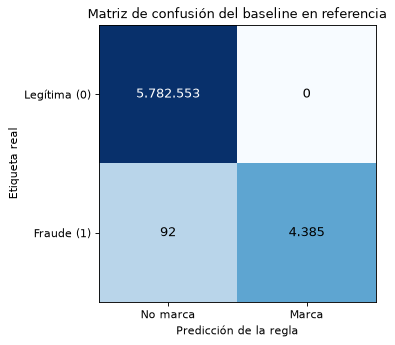

In [32]:
matrix = np.array(
    [
        [outcome.true_negatives, outcome.false_positives],
        [outcome.false_negatives, outcome.true_positives],
    ]
)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(np.log10(matrix + 1), cmap="Blues")
for (row, column), value in np.ndenumerate(matrix):
    color = "white" if value > 1_000_000 else "black"
    ax.text(
        column,
        row,
        f"{value:,}".replace(",", "."),
        ha="center",
        va="center",
        color=color,
        fontsize=12,
    )
ax.set_xticks([0, 1], ["No marca", "Marca"])
ax.set_yticks([0, 1], ["Legítima (0)", "Fraude (1)"])
ax.set_xlabel("Predicción de la regla")
ax.set_ylabel("Etiqueta real")
ax.set_title("Matriz de confusión del baseline en referencia")
plt.show()

La regla marca 4.385 transacciones y las 4.385 son fraude: cero falsos positivos. Deja sin
cubrir 92 fraudes. Precisión 1,000 y recall 0,979. Toda métrica de la fase 2 se reporta
contra este baseline. Como el PR-AUC global queda saturado por la región que la regla cubre,
la métrica de decisión será el punto de operación más allá de la regla, declarado antes de
ver resultados.

## 7. El Pipeline y sus dos configuraciones

`build_preprocessor` es una fábrica: cada llamada devuelve un `Pipeline` nuevo, porque un
objeto reutilizado entre folds es un objeto ya ajustado (ADR 0008). Tiene dos pasos:

1. `derive` conserva solo las columnas elegibles y agrega las derivadas.
2. `columns`, un único `ColumnTransformer`, envía cada columna seleccionada a una sola
   rama: monetarias (`log1p` y `RobustScaler`), categórica (one-hot que falla ante un tipo
   desconocido) y derivadas (pasan tal cual). Cada rama recibe solo sus columnas, así que
   leer la de otra rama levanta `KeyError`.

Las dos configuraciones son `full` y `no_signature`, la ablación del ADR 0007, sin
`oldbalanceOrg` ni la derivada de igualdad.

In [33]:
pd.DataFrame(
    [
        {"configuración": name, "rama": branch, "columnas": ", ".join(columns)}
        for name in CONFIGURATIONS
        for branch, _, columns in build_preprocessor(name).named_steps["columns"].transformers
    ]
)

,configuración,rama,columnas
0,full,money,"amount, oldbalanceOrg, oldbalanceDest"
1,full,categorical,type
2,full,derived,"amount_equals_origin_balance, hour_sin, hour_cos"
3,no_signature,money,"amount, oldbalanceDest"
4,no_signature,categorical,type
5,no_signature,derived,"hour_sin, hour_cos"


In [34]:
for name in CONFIGURATIONS:
    fitted = build_preprocessor(name).fit(reference)
    names = list(fitted.get_feature_names_out())
    print(f"{name}: {len(names)} features; 'step' entre ellas: {'step' in names}")
    print("   ", names)

full: 11 features; 'step' entre ellas: False
    ['amount', 'oldbalanceOrg', 'oldbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER', 'amount_equals_origin_balance', 'hour_sin', 'hour_cos']


no_signature: 9 features; 'step' entre ellas: False
    ['amount', 'oldbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER', 'hour_sin', 'hour_cos']


In [35]:
build_preprocessor("full").fit(reference).transform(reference.head(3))

,amount,oldbalanceOrg,oldbalanceDest,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,amount_equals_origin_balance,hour_sin,hour_cos
0,-0.743631,0.216802,-0.858995,0,0,0,1,0,False,0.258819,0.965926
1,-1.35007,0.0372067,-0.858995,0,0,0,1,0,False,0.258819,0.965926
2,-2.19865,-0.373751,-0.858995,0,0,0,0,1,True,0.258819,0.965926


Aquí el preprocesador se ajusta sobre todo el periodo de referencia solo para mostrar su
salida. En la fase 2 se ajusta dentro de cada partición de entrenamiento, con un objeto
nuevo por partición.

## 8. Qué hace la fase 2

- **Baselines primero:** el clasificador trivial y la regla de la firma, `SignatureRule`.
  Toda métrica se reporta con ellos al lado.
- **Prueba del target barajado:** el Pipeline completo con la etiqueta permutada tiene que
  colapsar al azar; si no colapsa, hay fuga.
- **AutoML con Optuna** sobre este Pipeline, con el algoritmo como un hiperparámetro más, y
  validación que respeta el orden temporal dentro de referencia.
- **La ablación `no_signature`**, una vez por familia de modelo, para medir cuánto del
  desempeño es la firma.
- **Registro en MLflow** del modelo ganador, con el mismo Pipeline serializado que usarán la
  interpretabilidad y el monitoreo.